# INSY 674 · Naive Bayes Modeling, Results and Interpretation

## 1 · Import and Initial Preparation

We only use scikit-learn for naive Bayes, so no extra package is needed (see `requirements.txt`).

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
    make_scorer, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
    ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, KBinsDiscretizer, OneHotEncoder

In [2]:
# Data files are in the project folder, next to this notebook
TRAIN_PATH = Path('train_raw.csv')
TEST_PATH = Path('test_raw.csv')

SEED = 42
N_SPLITS = 5
THRESHOLD = 0.5

# Many sessions have 0 page views or 0 duration, so some quantile cut points are the same.
# KBinsDiscretizer merges these bins and prints a warning every time, so we hide that warning.
warnings.filterwarnings('ignore', message='Bins whose width are too small')

In [3]:
TARGET = 'Revenue'
ID = 'source_row_id'
# Browsing behavior: page counts, time on pages, bounce/exit rates and page value
BROWSING = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']
# Visit context: calendar, visitor type, device, region and traffic source
CONTEXT_NUMERIC = ['SpecialDay', 'Weekend']
CATEGORICAL = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
FEATURES = BROWSING + CONTEXT_NUMERIC + CATEGORICAL   # same 17 predictors as in the other model notebooks

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

for name, df in [('train', train), ('test', test)]:
    missing_columns = sorted(set([ID, TARGET] + FEATURES) - set(df.columns))
    assert not missing_columns, f'{name} is missing columns: {missing_columns}'

shared_ids = set(train[ID]) & set(test[ID])
assert not shared_ids, 'Train and test share source_row_id values.'

display(pd.DataFrame({
    'rows': [len(train), len(test)],
    'missing values': [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    'purchases (Revenue = 1)': [int(train[TARGET].sum()), int(test[TARGET].sum())],
    'purchase rate': [round(train[TARGET].mean(), 4), round(test[TARGET].mean(), 4)],
}, index=['train', 'test']))
print('Shared source_row_id values between train and test:', len(shared_ids))

,rows,missing values,purchases (Revenue = 1),purchase rate
train,9764,0,1526,0.1563
test,2441,0,382,0.1565


Shared source_row_id values between train and test: 0


## 2 · Preprocessing

We drop `source_row_id` and only use `Revenue` as the target. `Weekend` is changed to 0/1, and the six code columns (`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`) are treated as categories, since a value like `TrafficType = 10` is just a label. The encoders are inside the pipeline, so in each CV fold they are fitted on the training part only.

For naive Bayes we also have to decide how to handle the continuous variables. `GaussianNB` assumes that every variable is normally distributed within each class. This does not fit our data well, because page counts, durations and `PageValues` are very right-skewed and often exactly 0. It also treats the 0/1 dummy columns as if they were normal, which is only a rough approximation. So we compare two options:

- `GaussianNB` on the raw or log-transformed values, with one-hot categories
- cutting each continuous variable into bins and using `BernoulliNB` on the 0/1 bin and category columns, so no normal distribution is needed

We do not scale the data. `GaussianNB` estimates its own mean and variance for each variable, and the binned version only has 0/1 columns.

In [4]:
for df in (train, test):
    df['Weekend'] = df['Weekend'].astype(int)
    df[CATEGORICAL] = df[CATEGORICAL].astype(str)

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

SKEWED = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
          'ProductRelated', 'ProductRelated_Duration', 'PageValues']
RATES = ['BounceRates', 'ExitRates', 'SpecialDay']
ENGINEERED = ['TotalPages', 'TotalDuration', 'ProductPageShare', 'DurationPerPage']   # only used in Section 4


def gaussian_model(log_transform=False):
    skewed = FunctionTransformer(np.log1p) if log_transform else 'passthrough'
    preprocess = ColumnTransformer([
        ('skewed', skewed, SKEWED),
        ('other', 'passthrough', RATES + ['Weekend']),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([('preprocess', preprocess), ('nb', GaussianNB())])


def binned_model(drop_columns=(), engineered=False, n_bins=5, alpha=1.0):
    # Continuous columns are cut into quantile bins. drop_columns is only used for the checks in Sections 6 and 8.
    continuous = [c for c in SKEWED + RATES if c not in drop_columns]
    if engineered:
        continuous = continuous + ENGINEERED
    preprocess = ColumnTransformer([
        ('bins', KBinsDiscretizer(n_bins=n_bins, encode='onehot-dense', strategy='quantile',
                                  quantile_method='averaged_inverted_cdf'), continuous),
        ('weekend', 'passthrough', ['Weekend']),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([('preprocess', preprocess), ('nb', BernoulliNB(alpha=alpha))])


print('Predictors:', len(FEATURES), '|', FEATURES)

Predictors: 17 | ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend', 'Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


## 3 · Baseline and Initial Naive Bayes

We use the same 5-fold stratified cross-validation (seed 42) as in the other model notebooks, so all models are tested on the same folds. Average precision (AP) is our main metric. It shows how well the model ranks buyers above non-buyers, and a random guess gets an AP close to the purchase rate (about 0.16). Precision, recall, F1 and accuracy use a 0.5 threshold. Train AP is the AP on the training part of each fold, which we use to check for overfitting. The baseline always predicts the training purchase rate. Our first naive Bayes model is a plain `GaussianNB` with default settings.

In [5]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
SCORING = {'AP': 'average_precision', 'ROC-AUC': 'roc_auc',
           'Precision': make_scorer(precision_score, zero_division=0), 'Recall': 'recall',
           'F1': make_scorer(f1_score, zero_division=0), 'Accuracy': 'accuracy'}


def mean_sd(fold_scores):
    # mean ± sample standard deviation (ddof=1) over the 5 folds, same as in the other notebooks
    return f'{np.mean(fold_scores):.4f} ± {np.std(fold_scores, ddof=1):.4f}'


def cv_row(model, X=None):
    X = X_train if X is None else X
    scores = cross_validate(model, X, y_train, cv=cv, scoring=SCORING, return_train_score=True)
    row = {m: mean_sd(scores['test_' + m]) for m in SCORING}
    row['Train AP'] = f"{scores['train_AP'].mean():.4f}"
    return row


cv_results = {
    'Dummy (prior)': cv_row(DummyClassifier(strategy='prior')),
    'Initial GaussianNB': cv_row(gaussian_model()),
}
display(pd.DataFrame(cv_results).T)

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,Train AP
Dummy (prior),0.1563 ± 0.0002,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.8437 ± 0.0002,0.1563
Initial GaussianNB,0.4192 ± 0.0149,0.7790 ± 0.0193,0.3350 ± 0.0175,0.6625 ± 0.0136,0.4448 ± 0.0180,0.7412 ± 0.0150,0.4347


The GaussianNB gets a CV AP of 0.419 compared to 0.156 for the baseline, and a ROC-AUC of 0.779, so it does pick up some signal. But it flags a lot of sessions as buyers. Recall is 66% while precision is only 34%, and accuracy (0.741) is even lower than the baseline (0.844). Train AP (0.435) is almost the same as the validation AP, so the model is not overfitting. The problem is rather that the normal distribution does not describe our variables.

## 4 · Feature Transformation and Engineering Check

Since the normal assumption does not fit, we try three changes and compare them with the same CV:

- a log transform `log(1 + x)` of the skewed columns
- binning: each continuous variable is cut into 5 quantile bins (about the same number of sessions in each bin), then `BernoulliNB` is used
- the binned model plus the four engineered features from the other notebooks (total pages, total duration, share of product pages, duration per page)

We only keep a change if CV AP goes up by more than one fold standard deviation.

In [6]:
pages = X_train['Administrative'] + X_train['Informational'] + X_train['ProductRelated']
X_train_eng = X_train.assign(
    TotalPages=pages,
    TotalDuration=X_train['Administrative_Duration'] + X_train['Informational_Duration'] + X_train['ProductRelated_Duration'],
)
X_train_eng['ProductPageShare'] = X_train_eng['ProductRelated'] / pages.replace(0, 1)
X_train_eng['DurationPerPage'] = X_train_eng['TotalDuration'] / pages.replace(0, 1)

transform_check = {
    'GaussianNB, raw features': cv_results['Initial GaussianNB'],
    'GaussianNB, log(1 + x) on skewed columns': cv_row(gaussian_model(log_transform=True)),
    'BernoulliNB, 5 quantile bins': cv_row(binned_model()),
    'BernoulliNB, 5 quantile bins + 4 engineered features': cv_row(binned_model(engineered=True), X_train_eng),
}
display(pd.DataFrame(transform_check).T[['AP', 'ROC-AUC', 'Recall', 'F1', 'Train AP']])

,AP,ROC-AUC,Recall,F1,Train AP
"GaussianNB, raw features",0.4192 ± 0.0149,0.7790 ± 0.0193,0.6625 ± 0.0136,0.4448 ± 0.0180,0.4347
"GaussianNB, log(1 + x) on skewed columns",0.3210 ± 0.0731,0.7551 ± 0.0592,0.9804 ± 0.0120,0.2999 ± 0.0055,0.3318
"BernoulliNB, 5 quantile bins",0.5249 ± 0.0273,0.8684 ± 0.0094,0.7379 ± 0.0349,0.6012 ± 0.0192,0.5233
"BernoulliNB, 5 quantile bins + 4 engineered features",0.4887 ± 0.0261,0.8497 ± 0.0098,0.7484 ± 0.0120,0.5463 ± 0.0168,0.4888


The log transform makes the model worse (AP 0.321) and also much less stable across folds (SD 0.073). After the log, all the zeros still form one big spike, so the data still don't look normal, and the model ends up predicting almost everyone as a buyer (recall 0.98).

Binning works much better. AP goes from 0.419 to 0.525 and ROC-AUC from 0.779 to 0.868, which is far more than one fold SD, so we keep the binned model.

Adding the engineered features lowers AP to 0.489. Naive Bayes treats each column as independent evidence, but a total like `TotalPages` mostly repeats the page counts that are already in the model. So the same information gets counted twice, and we leave the engineered features out.

## 5 · Hyperparameter Tuning

The binned model only has two settings:

- the number of bins per continuous variable
- `alpha`, the smoothing value. It adds a small count to every bin, so a bin that never appears in one class does not get a probability of exactly 0.

We only use quantile bins. We also tried k-means bins, but they gave warnings because a column like `SpecialDay` only has six different values and cannot be split into more bins than that. With 5 × 5 = 25 combinations we can simply try all of them, so we use `GridSearchCV` here instead of the random search we used for the tree models. Each combination is scored by AP on the same five folds, and the best one is refitted on the whole training set.

In [7]:
param_grid = {
    'preprocess__bins__n_bins': [3, 5, 8, 10, 15],
    'nb__alpha': [0.01, 0.1, 0.5, 1.0, 2.0],
}
search = GridSearchCV(binned_model(), param_grid, scoring=SCORING, refit='AP', cv=cv, return_train_score=True)
search.fit(X_train, y_train)
best_settings = {'n_bins': search.best_params_['preprocess__bins__n_bins'],
                 'alpha': search.best_params_['nb__alpha']}

# Top 3 combinations by mean CV AP (one column per combination)
results = pd.DataFrame(search.cv_results_).sort_values('rank_test_AP').head(3)
split_ap = results[[f'split{k}_test_AP' for k in range(N_SPLITS)]]
top3 = pd.concat([split_ap.mean(axis=1).rename('CV AP mean').round(4), split_ap.std(axis=1, ddof=1).rename('CV AP SD').round(4),
                  results[[c for c in results if c.startswith('param_')]]], axis=1)
top3.index = [f'rank {r}' for r in results['rank_test_AP']]
top3.columns = [c.replace('param_preprocess__bins__', '').replace('param_nb__', '') for c in top3.columns]
display(top3.T)

# Columns with many zeros get fewer bins than requested, because equal cut points are merged
bins_used = search.best_estimator_.named_steps['preprocess'].named_transformers_['bins'].n_bins_
print('Bins actually used per column:', dict(zip(SKEWED + RATES, bins_used.tolist())))

# Before vs after tuning, on the same folds
i = search.best_index_
cv_results['Binned BernoulliNB, 5 quantile bins'] = transform_check['BernoulliNB, 5 quantile bins']
cv_results['Tuned binned BernoulliNB'] = {m: mean_sd([search.cv_results_[f'split{k}_test_{m}'][i] for k in range(N_SPLITS)])
                                          for m in SCORING}
cv_results['Tuned binned BernoulliNB']['Train AP'] = f"{search.cv_results_['mean_train_AP'][i]:.4f}"
display(pd.DataFrame(cv_results).T)

,rank 1,rank 2,rank 3
CV AP mean,0.5355,0.5353,0.5352
CV AP SD,0.0258,0.0259,0.0254
alpha,2.0000,1.0000,0.5000
n_bins,10.0000,10.0000,10.0000


Bins actually used per column: {'Administrative': 6, 'Administrative_Duration': 6, 'Informational': 3, 'Informational_Duration': 2, 'ProductRelated': 10, 'ProductRelated_Duration': 10, 'PageValues': 3, 'BounceRates': 6, 'ExitRates': 10, 'SpecialDay': 2}


,AP,ROC-AUC,Precision,Recall,F1,Accuracy,Train AP
Dummy (prior),0.1563 ± 0.0002,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.8437 ± 0.0002,0.1563
Initial GaussianNB,0.4192 ± 0.0149,0.7790 ± 0.0193,0.3350 ± 0.0175,0.6625 ± 0.0136,0.4448 ± 0.0180,0.7412 ± 0.0150,0.4347
"Binned BernoulliNB, 5 quantile bins",0.5249 ± 0.0273,0.8684 ± 0.0094,0.5073 ± 0.0129,0.7379 ± 0.0349,0.6012 ± 0.0192,0.8471 ± 0.0060,0.5233
Tuned binned BernoulliNB,0.5355 ± 0.0258,0.8704 ± 0.0068,0.4734 ± 0.0111,0.7477 ± 0.0173,0.5797 ± 0.0103,0.8305 ± 0.0059,0.5383


The best setting is 10 bins with `alpha = 2`. The printout shows that 10 is only the maximum. Columns with many zeros get fewer bins, for example `PageValues` only gets 3. Compared with 5 bins, CV AP goes from 0.525 to 0.536 and ROC-AUC from 0.868 to 0.870. This is less than half a fold SD, so tuning does not change much. The top three combinations all use 10 bins and only differ in `alpha`, with almost the same AP, so the smoothing value hardly matters.

Train AP (0.538) is about the same as the validation AP, so there is no overfitting. Recall at 0.5 goes up a little but precision drops, so F1 is slightly lower than with 5 bins. Since the best score is picked out of 25 tries on the same folds, it might be a bit optimistic.

## 6 · `PageValues` Sensitivity Check

`PageValues` is the average value of the pages a user visited before completing a transaction. It comes from Google Analytics and is based on transaction revenue. The data do not tell us whether a session's value can include its own purchase, so we cannot rule out target leakage. To see how much the model depends on it, we run the CV again without `PageValues`, using the same tuned settings (this version is not tuned again).

In [8]:
sensitivity = {
    'Tuned BernoulliNB, with PageValues (main model)': cv_results['Tuned binned BernoulliNB'],
    'Same settings, without PageValues': cv_row(binned_model(drop_columns=['PageValues'], **best_settings)),
}
display(pd.DataFrame(sensitivity).T[['AP', 'ROC-AUC', 'Recall', 'F1']])

,AP,ROC-AUC,Recall,F1
"Tuned BernoulliNB, with PageValues (main model)",0.5355 ± 0.0258,0.8704 ± 0.0068,0.7477 ± 0.0173,0.5797 ± 0.0103
"Same settings, without PageValues",0.3126 ± 0.0228,0.7353 ± 0.0143,0.5439 ± 0.0242,0.3791 ± 0.0188


Without `PageValues`, AP drops from 0.536 to 0.313 and ROC-AUC from 0.870 to 0.735. That is a drop of about 40% in AP, so the model depends a lot on this one variable. A high score with `PageValues` does not prove that the variable is OK to use. If it partly contains the session's own purchase, our results overstate how well browsing behavior alone can predict buying.

## 7 · Threshold and Final Evaluation

We pick the threshold using out-of-fold (OOF) predictions on the training set, which means each session is predicted by a model that did not see it in training. We try thresholds from 0.05 to 0.95, keep the one with the highest F1 and compare it to 0.5. F1 just balances precision and recall, so this is not a business-based threshold. The test set is not used here.

In [9]:
def metrics_at(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'AP': average_precision_score(y_true, prob), 'ROC-AUC': roc_auc_score(y_true, prob),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred, zero_division=0), 'Accuracy': accuracy_score(y_true, pred),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}


oof = cross_val_predict(binned_model(**best_settings), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
candidate_thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
oof_f1 = [f1_score(y_train, (oof >= t).astype(int), zero_division=0) for t in candidate_thresholds]
CHOSEN_THRESHOLD = float(candidate_thresholds[np.argmax(oof_f1)])

display(pd.DataFrame({f'Training OOF, threshold {t:.2f}': metrics_at(y_train, oof, t)
                      for t in [THRESHOLD, CHOSEN_THRESHOLD]}).T.round(4))

# How confident is the model? Share of sessions with a very high probability, and how many of them really bought
very_sure = oof > 0.95
print(f'OOF probability above 0.95: {very_sure.mean():.1%} of sessions, '
      f'and {y_train[very_sure].mean():.1%} of these sessions actually bought.')

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
"Training OOF, threshold 0.50",0.5307,0.8703,0.4732,0.7477,0.5796,0.8305,6968.0,1270.0,385.0,1141.0
"Training OOF, threshold 0.69",0.5307,0.8703,0.5156,0.6940,0.5916,0.8503,7243.0,995.0,467.0,1059.0


OOF probability above 0.95: 13.7% of sessions, and 58.1% of these sessions actually bought.


The best OOF threshold is 0.69, which is higher than 0.5. The printout shows why: naive Bayes is overconfident. About 14% of the sessions get a probability above 0.95, but only 58% of those sessions actually bought something. At 0.5 the model flags too many sessions (1,270 false positives vs 1,141 true positives). Moving the threshold to 0.69 removes about 275 false positives (1,270 to 995), but recall drops from 0.75 to 0.69, and F1 only goes from 0.58 to 0.59.

Both thresholds are fixed now. The tuned model, refitted on all training data, is evaluated once on the test set.

,AP,ROC-AUC,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
Dummy (prior),0.1565,0.5000,0.0000,0.000,0.0000,0.8435,2059.0,0.0,382.0,0.0
"Tuned naive Bayes, threshold 0.50",0.5576,0.8783,0.4827,0.767,0.5925,0.8349,1745.0,314.0,89.0,293.0
"Tuned naive Bayes, threshold 0.69",0.5576,0.8783,0.5235,0.699,0.5987,0.8533,1816.0,243.0,115.0,267.0


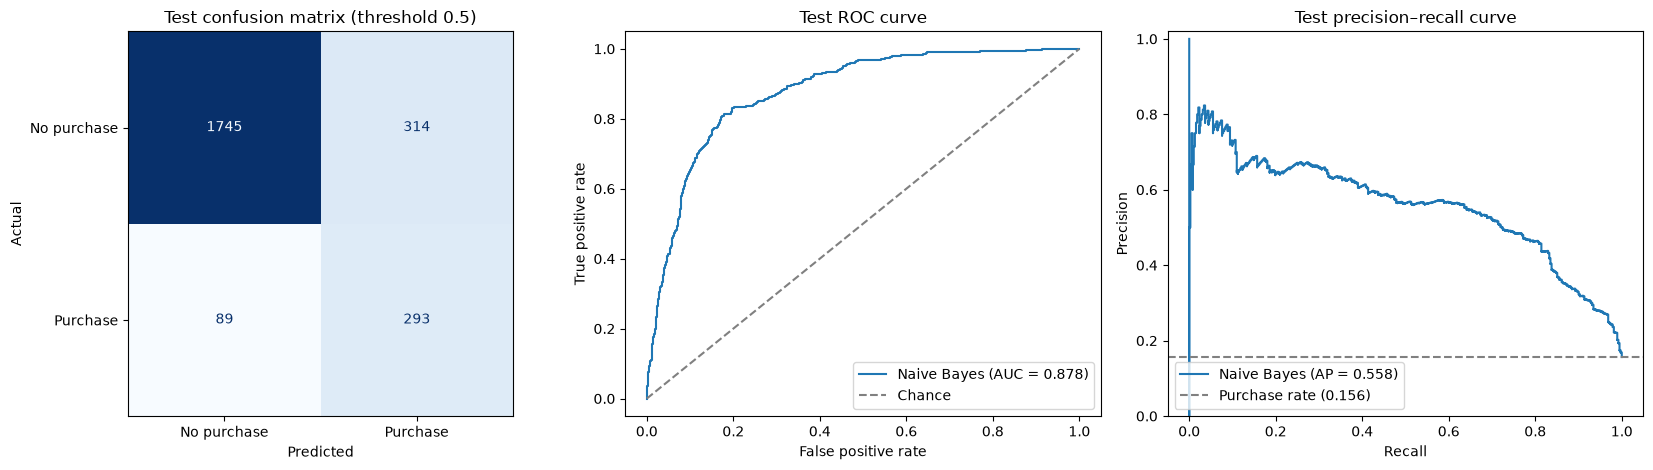

In [10]:
final_model = search.best_estimator_
p_test = final_model.predict_proba(X_test)[:, 1]
p_dummy = DummyClassifier(strategy='prior').fit(X_train, y_train).predict_proba(X_test)[:, 1]

display(pd.DataFrame({
    'Dummy (prior)': metrics_at(y_test, p_dummy, THRESHOLD),
    'Tuned naive Bayes, threshold 0.50': metrics_at(y_test, p_test, THRESHOLD),
    f'Tuned naive Bayes, threshold {CHOSEN_THRESHOLD:.2f}': metrics_at(y_test, p_test, CHOSEN_THRESHOLD),
}).T.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= THRESHOLD).astype(int),
                                        display_labels=['No purchase', 'Purchase'], ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set(title=f'Test confusion matrix (threshold {THRESHOLD})', xlabel='Predicted', ylabel='Actual')

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, label=f'Naive Bayes (AUC = {roc_auc_score(y_test, p_test):.3f})')
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Chance')
axes[1].set(title='Test ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[1].legend(loc='lower right')

precision, recall, _ = precision_recall_curve(y_test, p_test)
axes[2].step(recall, precision, where='post', label=f'Naive Bayes (AP = {average_precision_score(y_test, p_test):.3f})')
axes[2].axhline(y_test.mean(), ls='--', color='gray', label=f'Purchase rate ({y_test.mean():.3f})')
axes[2].set(title='Test precision–recall curve', xlabel='Recall', ylabel='Precision', ylim=(0, 1.02))
axes[2].legend(loc='lower left')
fig.tight_layout(); plt.show(); plt.close(fig)

On the test set the model gets an AP of 0.558 and a ROC-AUC of 0.878, which is a little higher than in CV, so it works fine on sessions it has not seen. The test set comes from the same data (random split), so this does not tell us how the model would do in a later time period.

At 0.5, it finds 293 of the 382 buyers (recall 77%), but only 48% of the sessions it flags actually buy. It misses 89 buyers and wrongly flags 314 non-buyers. At 0.69 it finds 267 buyers, false positives go down from 314 to 243, and F1 stays about the same (0.593 vs 0.599).

The ROC curve has an area of 0.878 (0.5 would be random guessing), and the PR curve has an AP of 0.558 compared to a purchase rate of 0.156. When comparing with the other models we use the 0.5 results.

## 8 · Feature Importance and Error Analysis

We compute permutation importance on the CV validation folds. In each fold we shuffle one column at a time (5 times), check how much AP drops and then average over the 5 folds. Each original variable is shuffled before binning and one-hot encoding, so a category like `Month` is shuffled as one variable.

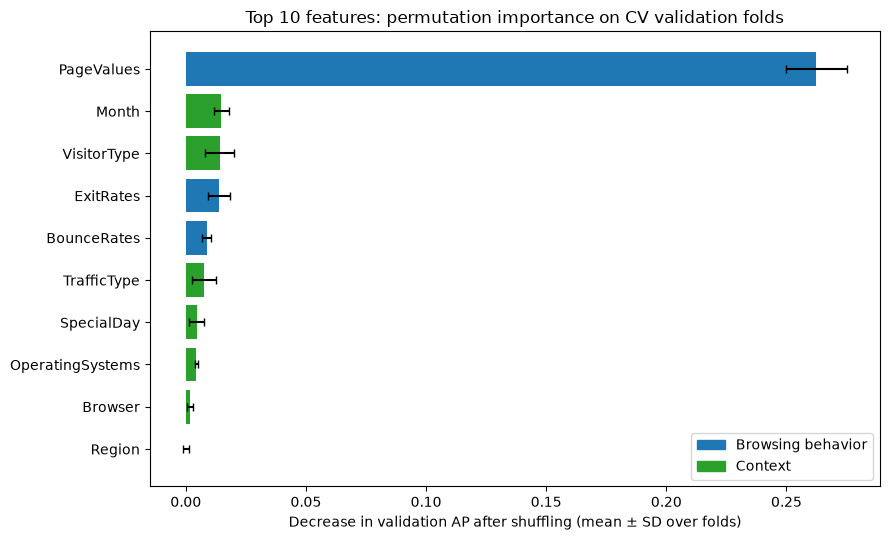

,AP drop (mean over folds),SD over folds,group
PageValues,0.2624,0.0127,browsing behavior
Month,0.0148,0.0031,context
VisitorType,0.0141,0.0059,context
ExitRates,0.0138,0.0045,browsing behavior
BounceRates,0.0087,0.0020,browsing behavior
TrafficType,0.0076,0.0048,context
SpecialDay,0.0045,0.0032,context
OperatingSystems,0.0044,0.0006,context
Browser,0.0017,0.0012,context
Region,0.0001,0.0013,context


In [11]:
fold_importance = []
for train_idx, val_idx in cv.split(X_train, y_train):
    model = binned_model(**best_settings).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    result = permutation_importance(model, X_train.iloc[val_idx], y_train.iloc[val_idx],
                                    scoring='average_precision', n_repeats=5, random_state=SEED)
    fold_importance.append(result.importances_mean)

importance = pd.DataFrame({'AP drop (mean over folds)': np.mean(fold_importance, axis=0),
                           'SD over folds': np.std(fold_importance, axis=0, ddof=1)}, index=FEATURES)
importance['group'] = ['browsing behavior' if f in BROWSING else 'context' for f in FEATURES]
top10 = importance.sort_values('AP drop (mean over folds)', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_data = top10.iloc[::-1]
ax.barh(plot_data.index, plot_data['AP drop (mean over folds)'], xerr=plot_data['SD over folds'], capsize=3,
        color=['tab:blue' if g == 'browsing behavior' else 'tab:green' for g in plot_data['group']])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ['tab:blue', 'tab:green']],
          labels=['Browsing behavior', 'Context'], loc='lower right')
ax.set(title='Top 10 features: permutation importance on CV validation folds',
       xlabel='Decrease in validation AP after shuffling (mean ± SD over folds)')
fig.tight_layout(); plt.show(); plt.close(fig)

# Full table with all 17 features, because some of them have negative importance
display(importance.sort_values('AP drop (mean over folds)', ascending=False).round(4))

`PageValues` is by far the most important variable (AP drop of 0.26). All others are much smaller: `Month` (0.015), `VisitorType` (0.014) and `ExitRates` (0.014), then `BounceRates` and `TrafficType`.

What is surprising is that the page-count and duration variables (`Administrative`, `Informational`, `ProductRelated` and their durations) have negative importance, so AP actually gets a bit better when we shuffle them. Our guess is that this comes from the independence assumption. Each page count is strongly correlated with its duration (see the EDA notebook), but naive Bayes counts them as separate evidence, so the same information is used twice. We check this below.

Keep in mind that importance only shows how much the model uses a variable. It does not show a causal effect or whether the effect is positive or negative.

### Follow-up check: removing duplicated information

If double counting is the problem, removing the duplicated columns should help. We run the CV again with the tuned settings, once without the three duration columns and once without all six page-count and duration columns. This only uses the training folds. The final model was already evaluated on the test set, so we do not change it based on this check.

In [12]:
DURATIONS = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']
PAGE_COUNTS = ['Administrative', 'Informational', 'ProductRelated']

overlap_check = {
    'Tuned model, all features': cv_results['Tuned binned BernoulliNB'],
    'Without the 3 duration columns': cv_row(binned_model(drop_columns=DURATIONS, **best_settings)),
    'Without all 6 page-count and duration columns': cv_row(binned_model(drop_columns=DURATIONS + PAGE_COUNTS, **best_settings)),
}
display(pd.DataFrame(overlap_check).T[['AP', 'ROC-AUC', 'F1']])

,AP,ROC-AUC,F1
"Tuned model, all features",0.5355 ± 0.0258,0.8704 ± 0.0068,0.5797 ± 0.0103
Without the 3 duration columns,0.5933 ± 0.0211,0.8859 ± 0.0062,0.6207 ± 0.0122
Without all 6 page-count and duration columns,0.6613 ± 0.0123,0.8897 ± 0.0085,0.6477 ± 0.0110


Removing the three duration columns raises CV AP from 0.536 to 0.593, and removing all six page-count and duration columns raises it to 0.661. ROC-AUC and F1 go up as well. Both AP gains are bigger than two fold SDs, so the double counting really does hurt this model. For naive Bayes it would have been better to use a smaller set of features that overlap less. We only found this after the test evaluation, so we keep it as a lesson learned and a possible next step instead of changing the final model.

The table below groups the training OOF predictions of the final model at the 0.5 threshold.

In [13]:
oof_pred = (oof >= THRESHOLD).astype(int)
train['outcome'] = np.select(
    [(y_train == 1) & (oof_pred == 1), (y_train == 1) & (oof_pred == 0), (y_train == 0) & (oof_pred == 1)],
    ['true positive', 'false negative (missed buyer)', 'false positive (false alarm)'], default='true negative')

error_table = train.groupby('outcome').agg(
    sessions=(TARGET, 'size'),
    median_page_value=('PageValues', 'median'),
    median_product_pages=('ProductRelated', 'median'),
    median_product_duration=('ProductRelated_Duration', 'median'),
    median_exit_rate=('ExitRates', 'median'),
)
display(error_table.round(3))

,sessions,median_page_value,median_product_pages,median_product_duration,median_exit_rate
outcome,,,,,
false negative (missed buyer),385,0.000,19.0,650.833,0.027
false positive (false alarm),1270,5.514,46.0,1715.917,0.016
true negative,6968,0.000,13.0,399.000,0.033
true positive,1141,22.656,32.0,1226.000,0.014


The missed buyers are mostly short sessions. Their median page value is 0, they looked at 19 product pages (median) and they have higher exit rates, so for the model they look like non-buyers. The false alarms are long browsing sessions with a median of 46 product pages and low exit rates, and many of them have some page value (median 5.5). In naive Bayes every sign of engagement adds up separately, so a lot of browsing can push a session over the threshold even if the person does not buy. To tell these sessions apart we would need data we do not have, like add-to-cart events, prices or promotions.

## 9 · Conclusion and Limitations

Naive Bayes predicts purchases clearly better than the baseline. On the test set it gets an AP of 0.558 (baseline 0.156) and a ROC-AUC of 0.878. At the 0.5 threshold it finds 77% of the buyers, but only 48% of the sessions it flags actually buy. The most important step was binning the continuous variables, which raised CV AP from 0.419 to 0.525. The log transform and the engineered features made the model worse, and tuning did not add much.

For this model the most useful browsing variables are page value, exit rate and bounce rate, and the most useful context variables are month and visitor type. The page-count and duration variables do not help, because their information is counted twice.

This model makes different mistakes than the tree models in our other notebooks: it misses fewer buyers but gives many more false alarms. This could make it useful in an ensemble.

Limitations:

- The independence assumption clearly does not hold. Correlated columns are counted twice and the probabilities are overconfident. Dropping the duplicated columns improved CV AP a lot, but we only found this after the test evaluation, so the final model does not include it.
- The model depends a lot on `PageValues` (AP drops by about 40% without it). If this variable contains information about the purchase itself, part of the performance comes from leakage.
- The data describe complete sessions, so we can only say the model works after the fact, not in real time during a visit.
- Only about 16% of sessions are purchases, so precision is low and the results depend on the threshold. The 0.69 threshold is based on F1, not on real costs.
- The tuned CV score is a bit optimistic because it was picked from 25 combinations on the same folds, and all data come from one year.

The table below collects the numbers for the group comparison (CV mean ± SD over the five folds, and test results at the 0.5 threshold).

In [14]:
group_summary = {'CV ' + m: cv_results['Tuned binned BernoulliNB'][m] for m in ['AP', 'ROC-AUC', 'F1']}
test_at_05 = metrics_at(y_test, p_test, THRESHOLD)
group_summary.update({'Test ' + m: round(test_at_05[m], 4) for m in ['AP', 'ROC-AUC', 'Precision', 'Recall', 'F1', 'Accuracy']})
display(pd.DataFrame(group_summary, index=['Naive Bayes (tuned binned BernoulliNB, 17 raw features)']).T)

,"Naive Bayes (tuned binned BernoulliNB, 17 raw features)"
CV AP,0.5355 ± 0.0258
CV ROC-AUC,0.8704 ± 0.0068
CV F1,0.5797 ± 0.0103
Test AP,0.5576
Test ROC-AUC,0.8783
Test Precision,0.4827
Test Recall,0.767
Test F1,0.5925
Test Accuracy,0.8349
